<div class="alert alert-info" role="alert"
     style="font-size: 1.55em; font-weight: bold; padding: 15px; margin: 10px 0; text-align: left; background-color: #d9edf7; border-color: #bce8f1; color: #31708f; border-radius: 8px;">
    Cloud fraction inside the Sargassum belt vs just outside it, before and after 2011
</div>

### Basic set up ▶▶ Libraries and shared helpers (`cf_checks/cf_common.py`)

In [1]:
import sys
import numpy as np
import pandas as pd
import xarray as xr
import regionmask
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pathlib import Path
from scipy import ndimage
from scipy.stats import ttest_ind

sys.path.append("/home/nandii/cloudML/cf_checks")
from cf_common import *
set_fonts()

# Gridliner labels give NaN bounding boxes, which breaks bbox_inches = "tight" (colorbar-only output)
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}

### Belt and ring ▶▶ from OLCI detections on the 0.25 deg cloud grid
Belt: ocean cells with Sargassum detected in at least 5 of the 44 bloom-season months (May-Aug 2016-2026).
Ring: ocean cells within 2 deg of a belt cell, not in the belt. Both inside the 60W-20W analysis box.
The same masks are used for every year of every dataset.

In [2]:
sg = xr.open_zarr("/home/nandii/olci_sg/All_Sargassum_Detects.zarr")
sg = sg.sel(time = sg.time.dt.month.isin(BLOOM_MONTHS))
n_months = sg.sizes["time"]

# 5 x 5 blocks of 0.05 deg = one 0.25 deg cell; put them on the CLARA-A3 cell centres
det = sg["detect_count"].coarsen(lat = 5, lon = 5).sum().compute()
det = det.assign_coords(lat = np.round(np.arange(-4.875, 20.0, 0.25), 3).astype("float32"),
                        lon = np.round(np.arange(-69.875, -20.0, 0.25), 3).astype("float32"))
months_with = (det > 0).sum("time").sel(lon = LON_SLICE)

ocean = np.isnan(regionmask.defined_regions.natural_earth_v5_0_0.land_110.mask(months_with.lon, months_with.lat))
belt = (months_with >= 5) & ocean
# Distance in cells from the nearest belt cell, 0.25 deg each
dist_deg = xr.DataArray(ndimage.distance_transform_edt(~belt.values) * 0.25, coords = belt.coords)
ring = (dist_deg <= 2) & ~belt & ocean
print(f"belt: {int(belt.sum())} cells, ring: {int(ring.sum())} cells")

belt: 719 cells, ring: 3481 cells


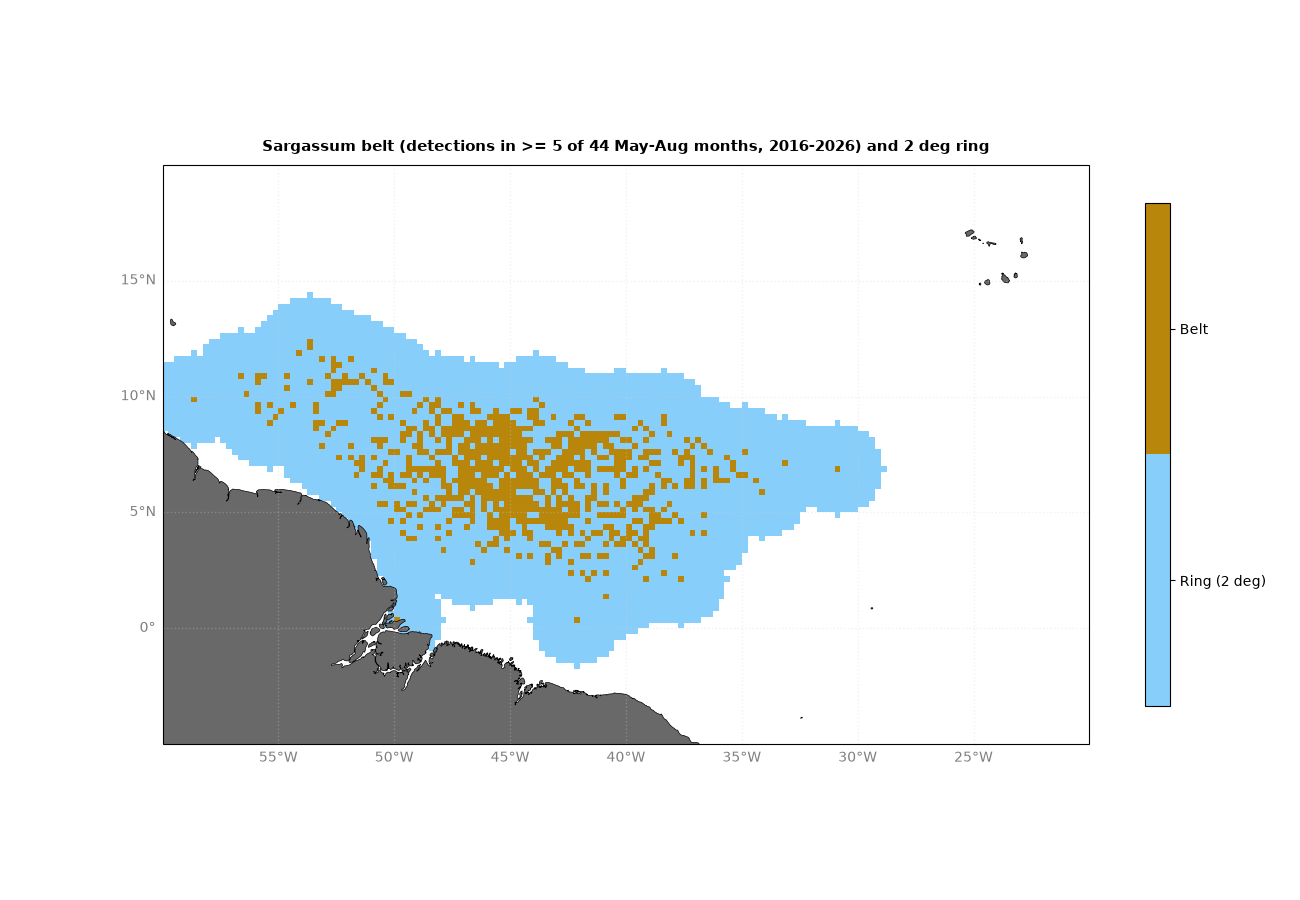

In [3]:
pc = ccrs.PlateCarree()
fig = plt.figure(figsize = (13, 9))
ax = plt.axes(projection = pc)
region = xr.where(belt, 2, xr.where(ring, 1, np.nan))
im = ax.pcolormesh(region.lon, region.lat, region, cmap = mcolors.ListedColormap(['lightskyblue', 'darkgoldenrod']),
                   transform = pc)
im.set_clim(0.5, 2.5)
ax.set_extent([-60, -20, -5, 20], crs = pc)
ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '10m', linewidth = 0.5,
                                             edgecolor = 'black', facecolor = 'dimgrey'))
gl = ax.gridlines(crs = pc, draw_labels = True, linewidth = 1, color = 'lightgray', alpha = 0.3, linestyle = ':')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 10, 'color': 'grey'}
gl.ylabel_style = {'size': 10, 'color': 'grey'}
cbar = plt.colorbar(im, orientation = "vertical", fraction = 0.025, pad = 0.055, ticks = [1, 2])
cbar.ax.set_yticklabels(['Ring (2 deg)', 'Belt'])
ax.set_title(f'Sargassum belt (detections in >= 5 of {n_months} May-Aug months, 2016-2026) and 2 deg ring',
             fontsize = 11, weight = 'bold', pad = 10, y = 1.0)
plt.show()

In [4]:
fig.savefig('Sargassum_belt_ring_mask.png', dpi = 300)

### Convection ▶▶ CLARA-A3 monthly OLR (`LW_flux`, TOA outgoing longwave), mean May-Aug 2016-2026
Same years as the Sargassum detections. Contours: 240 W/m² (deep convection) and 220 W/m² (strongest convection).

In [5]:
fs = s3fs.S3FileSystem(profile = "laurenb", client_kwargs = {"endpoint_url": "https://s3.waw3-1.cloudferro.com"})
olr_files = [f for f in fs.ls("clara_olr_mm")
             if 2016 <= int(f.split("OLRmm")[1][:4]) <= 2026 and int(f.split("OLRmm")[1][4:6]) in BLOOM_MONTHS]
olr = xr.concat([xr.open_dataset(fs.open(f), engine = "h5netcdf")["LW_flux"].sel(lat = slice(-5, 20), lon = slice(-60, -20)).load()
                 for f in olr_files], dim = "time")
olr_mean = olr.mean("time")
print(f"{olr.sizes['time']} months, OLR {float(olr_mean.min()):.0f} to {float(olr_mean.max()):.0f} W/m²")

44 months, OLR 223 to 287 W/m²


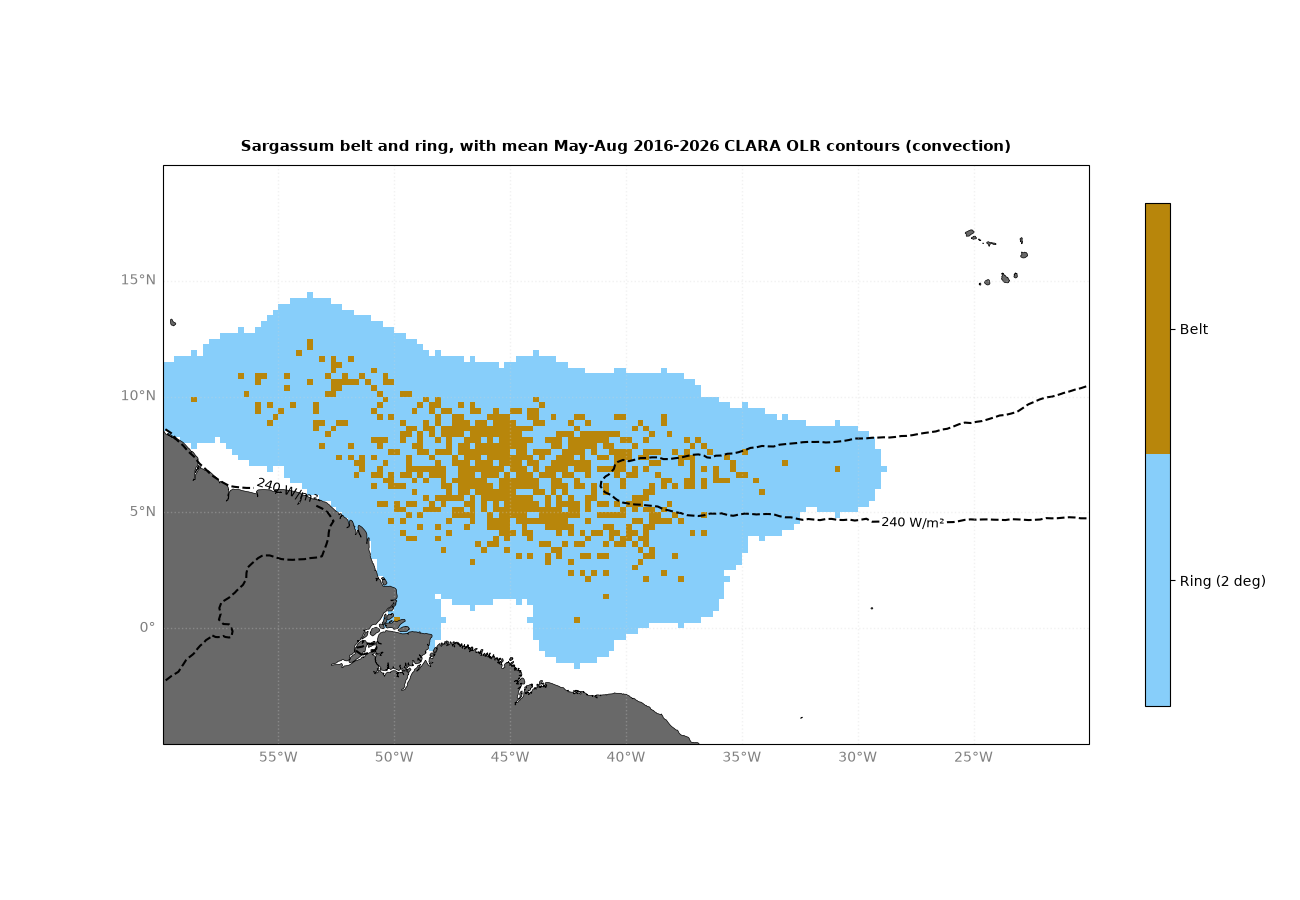

In [6]:
fig = plt.figure(figsize = (13, 9))
ax = plt.axes(projection = pc)
im = ax.pcolormesh(region.lon, region.lat, region, cmap = mcolors.ListedColormap(['lightskyblue', 'darkgoldenrod']),
                   transform = pc)
im.set_clim(0.5, 2.5)
cs = ax.contour(olr_mean.lon, olr_mean.lat, olr_mean, levels = [220, 240], colors = 'black',
                linestyles = ['-', '--'], linewidths = 1.5, transform = pc)
ax.clabel(cs, fontsize = 9, inline = True, fmt = '%d W/m²')
ax.set_extent([-60, -20, -5, 20], crs = pc)
ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '10m', linewidth = 0.5,
                                             edgecolor = 'black', facecolor = 'dimgrey'))
gl = ax.gridlines(crs = pc, draw_labels = True, linewidth = 1, color = 'lightgray', alpha = 0.3, linestyle = ':')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 10, 'color': 'grey'}
gl.ylabel_style = {'size': 10, 'color': 'grey'}
cbar = plt.colorbar(im, orientation = "vertical", fraction = 0.025, pad = 0.055, ticks = [1, 2])
cbar.ax.set_yticklabels(['Ring (2 deg)', 'Belt'])
ax.set_title('Sargassum belt and ring, with mean May-Aug 2016-2026 CLARA OLR contours (convection)',
             fontsize = 11, weight = 'bold', pad = 10, y = 1.0)
plt.show()

In [7]:
fig.savefig('Sargassum_belt_ring_OLR.png', dpi = 300)

### Load data ▶▶ daily OCA, MODIS Terra + Aqua (pooled) and CLARA, mean over belt and ring cells
MODIS uses whichever yearly files exist (the build is still running), pooled as in `modis_cf/2MODIS_OCA_Comparison.ipynb`:
(cloudy Terra + cloudy Aqua) / (valid Terra + valid Aqua), cell-days with both satellites only.
Each dataset is used on its own full record; no matching of days between datasets.

In [8]:
oca = load_grid("cf_scene", OCA_STORES)
cfc = load_grid("cfc", CLARA_STORES)

year_dir = Path("/home/nandii/cloudML/modis_cf_025_years")
modis = {}
for sat in ["terra", "aqua"]:
    ds = xr.concat([xr.open_dataset(f) for f in sorted(year_dir.glob(f"MODIScf025_{sat}_*.nc"))], dim = "time")
    modis[sat] = ds.assign_coords(lat = ds.lat.astype("float32"), lon = ds.lon.astype("float32")).sel(lon = LON_SLICE)

# Pooled Terra + Aqua cloud fraction, cell-days with both satellites only
t, a = xr.align(modis["terra"], modis["aqua"], join = "inner")
both_sats = (t["n_terra"] > 0) & (a["n_aqua"] > 0)
n_cloud = t["cf_terra"] / 100 * t["n_terra"] + a["cf_aqua"] / 100 * a["n_aqua"]
mod = (n_cloud / (t["n_terra"] + a["n_aqua"]) * 100).where(both_sats).astype("float32")
mod = mod.sel(time = mod.time.dt.month.isin(BLOOM_MONTHS))

daily = {}
for name, da in [("OCA", oca), ("MODIS T+A", mod), ("CLARA", cfc)]:
    df = pd.DataFrame({"belt": box_series(da.where(belt)), "ring": box_series(da.where(ring))}).dropna()
    daily[name] = df.assign(diff = df["belt"] - df["ring"])
    print(f"{name}: {len(df)} days, {df.index.min().date()} to {df.index.max().date()}")

weekly = {name: df.resample("W").mean().dropna() for name, df in daily.items()}

OCA: 1961 days, 2004-05-01 to 2019-08-31


MODIS T+A: 1644 days, 2002-07-04 to 2015-08-31


CLARA: 4516 days, 1990-05-01 to 2026-07-28


### Statistics ▶▶ weekly means per block, and post-2011 minus pre-2011
Pre-2011: to 2010-08-31. Post-2011: from 2011-05-01. p: Welch t-test, post vs pre weekly values.

In [9]:
rows = {}
for name, w in weekly.items():
    pre, post = w[w.index < SPLIT], w[w.index >= SPLIT]
    for block, d in [("pre-2011", pre), ("post-2011", post)]:
        rows[(name, block)] = {"years": f"{d.index.year.min()}-{d.index.year.max()}", "weeks": len(d),
                               "belt": d["belt"].mean(), "ring": d["ring"].mean(), "belt - ring": d["diff"].mean()}
    change = {col: post[col].mean() - pre[col].mean() for col in ["belt", "ring", "diff"]}
    rows[(name, "post - pre")] = {"years": "", "weeks": np.nan, "belt": change["belt"], "ring": change["ring"],
                                  "belt - ring": change["diff"]}
    rows[(name, "p (post vs pre)")] = {"years": "", "weeks": np.nan,
                                       **{lab: ttest_ind(post[col], pre[col], equal_var = False).pvalue
                                          for lab, col in [("belt", "belt"), ("ring", "ring"), ("belt - ring", "diff")]}}
stats = pd.DataFrame(rows).T
stats[["belt", "ring", "belt - ring"]] = stats[["belt", "ring", "belt - ring"]].astype(float).round(3)
stats

years weeks    belt    ring  belt - ring
OCA       pre-2011         2004-2010   130  71.641  67.370        4.270
          post-2011        2011-2019   165  71.457  66.826        4.630
          post - pre                   NaN  -0.184  -0.544        0.360
          p (post vs pre)              NaN   0.864   0.558        0.549
MODIS T+A pre-2011         2002-2010   157  70.788  66.008        4.780
          post-2011        2011-2015    92  69.928  65.360        4.568
          post - pre                   NaN  -0.860  -0.648       -0.212
          p (post vs pre)              NaN   0.502   0.565        0.723
CLARA     pre-2011         1990-2010   387  68.298  62.806        5.492
          post-2011        2011-2026   290  66.601  61.347        5.254
          post - pre                   NaN  -1.697  -1.459       -0.238
          p (post vs pre)              NaN   0.025   0.026        0.582

In [10]:
# Mean belt - ring per season
pd.concat({name: df.groupby(df.index.year)["diff"].mean() for name, df in daily.items()}, axis = 1).sort_index().round(2)

,OCA,MODIS T+A,CLARA
1990,NaN,NaN,6.56
1991,NaN,NaN,4.75
1992,NaN,NaN,8.98
1993,NaN,NaN,5.69
1994,NaN,NaN,6.41
1995,NaN,NaN,5.26
1996,NaN,NaN,2.40
1997,NaN,NaN,7.58
1998,NaN,NaN,5.42
1999,NaN,NaN,3.97


### Trends ▶▶ weekly CF in the belt, the ring and the ITCZ (mean May-Aug 2016-2026 OLR < 240 W/m², ocean), full record and pre/post-2011
OLS on calendar time (`trend_stats`), total change in pp over each block, as in notebook 3.

In [11]:
itcz = (olr_mean < 240).assign_coords(lat = belt.lat, lon = belt.lon) & ocean
print(f"ITCZ: {int(itcz.sum())} cells, of which {int((itcz & belt).sum())} also in the belt")

rows = {}
for name, da in [("OCA", oca), ("MODIS T+A", mod), ("CLARA", cfc)]:
    for region, mask in [("belt", belt), ("ring", ring), ("ITCZ", itcz)]:
        w = box_series(da.where(mask)).resample("W").mean().dropna()
        for block, s in [("full", w), ("pre-2011", w[w.index < SPLIT]), ("post-2011", w[w.index >= SPLIT])]:
            ts = trend_stats(s.index, s.values)
            rows[(name, region, block)] = {"years": f"{s.index.year.min()}-{s.index.year.max()}", "weeks": len(s),
                                           "total_pp": round(ts["total"], 2), "p": round(ts["p_val"], 4)}
trends = pd.DataFrame(rows).T
trends

ITCZ: 1166 cells, of which 57 also in the belt


years weeks total_pp       p
OCA       belt full       2004-2019   295     0.83   0.634
               pre-2011   2004-2010   130    -1.21  0.6479
               post-2011  2011-2019   165     4.16  0.0532
          ring full       2004-2019   295     0.63   0.677
               pre-2011   2004-2010   130     1.37   0.542
               post-2011  2011-2019   165     3.49  0.0683
          ITCZ full       2004-2019   295     1.24  0.5626
               pre-2011   2004-2010   130     1.01  0.7597
               post-2011  2011-2019   165     3.66   0.158
MODIS T+A belt full       2002-2015   249     -0.9  0.6703
               pre-2011   2002-2010   157    -0.67  0.8002
               post-2011  2011-2015    92     3.61  0.2365
          ring full       2002-2015   249     0.48  0.7948
               pre-2011   2002-2010   157     2.21  0.3386
               post-2011  2011-2015    92     3.07  0.2541
          ITCZ full       2002-2015   249    -0.47  0.7755
               pre-2011   2002-2010   157     0.83  0.6791
               post-2011  2011-2015    92     5.86  0.0176
CLARA     belt full       1990-2026   677    -3.75  0.0034
               pre-2011   1990-2010   387    -5.17   0.002
               post-2011  2011-2026   290     2.34  0.2163
          ring full       1990-2026   677     -2.8  0.0118
               pre-2011   1990-2010   387    -3.38  0.0197
               post-2011  2011-2026   290     2.38  0.1491
          ITCZ full       1990-2026   677    -2.27  0.0939
               pre-2011   1990-2010   387    -2.87  0.0983
               post-2011  2011-2026   290     2.65  0.1995

### Per-pixel trends ▶▶ weekly May-Aug CF, full record and pre/post-2011, p < 0.05 only
Same per-pixel OLS as notebook 6. Black dashed: Sargassum belt and the outer edge of the 2 deg ring. Purple dashed: mean OLR 240 W/m².

In [12]:
from scipy import stats

# OLS trend per pixel on calendar time, same as linregress but vectorised over the grid; NaN weeks skipped per pixel
def pixel_trends(da):
    x = (da.time.values - da.time.values[0]) / np.timedelta64(1, "D")
    y = da.values
    ok = np.isfinite(y)
    n = ok.sum(axis = 0)
    xs = np.where(ok, x[:, None, None], np.nan)
    x_bar, y_bar = np.nanmean(xs, axis = 0), np.nanmean(y, axis = 0)
    sxx = np.nansum((xs - x_bar) ** 2, axis = 0)
    sxy = np.nansum((xs - x_bar) * (y - y_bar), axis = 0)
    slope = sxy / sxx
    resid = y - (y_bar + slope * (xs - x_bar))
    se = np.sqrt(np.nansum(resid ** 2, axis = 0) / (n - 2) / sxx)
    p_val = 2 * stats.t.sf(np.abs(slope / se), n - 2)
    coords = {"lat": da.lat, "lon": da.lon}
    total = xr.DataArray(np.where(n > 2, slope * x.max(), np.nan), coords = coords, dims = ["lat", "lon"])
    p_val = xr.DataArray(np.where(n > 2, p_val, np.nan), coords = coords, dims = ["lat", "lon"])
    return total, p_val

pix = {}
for name, da in [("OCA", oca), ("MODIS T+A", mod), ("CLARA", cfc)]:
    w = da.resample(time = "W").mean().compute().dropna("time", how = "all")
    for block, sub in [("full", w), ("pre-2011", w.sel(time = w.time < SPLIT)), ("post-2011", w.sel(time = w.time >= SPLIT))]:
        total, p_val = pixel_trends(sub)
        years = f"{str(sub.time.values[0])[:4]}-{str(sub.time.values[-1])[:4]}"
        pix[(name, block)] = (total.where(p_val < 0.05), years)
        print(f"{name} {block} {years}: {sub.sizes['time']} weeks, "
              f"{float((p_val < 0.05).sum() / total.notnull().sum() * 100):.0f}% of pixels p < 0.05")

/tmp/ipykernel_2010570/4002195882.py:10: RuntimeWarning: Mean of empty slice
  x_bar, y_bar = np.nanmean(xs, axis = 0), np.nanmean(y, axis = 0)
/tmp/ipykernel_2010570/4002195882.py:13: RuntimeWarning: invalid value encountered in divide
  slope = sxy / sxx
/tmp/ipykernel_2010570/4002195882.py:15: RuntimeWarning: invalid value encountered in divide
  se = np.sqrt(np.nansum(resid ** 2, axis = 0) / (n - 2) / sxx)
/tmp/ipykernel_2010570/4002195882.py:10: RuntimeWarning: Mean of empty slice
  x_bar, y_bar = np.nanmean(xs, axis = 0), np.nanmean(y, axis = 0)


OCA full 2004-2019: 295 weeks, 7% of pixels p < 0.05
OCA pre-2011 2004-2010: 130 weeks, 15% of pixels p < 0.05
OCA post-2011 2011-2019: 165 weeks, 9% of pixels p < 0.05


/tmp/ipykernel_2010570/4002195882.py:13: RuntimeWarning: invalid value encountered in divide
  slope = sxy / sxx
/tmp/ipykernel_2010570/4002195882.py:15: RuntimeWarning: invalid value encountered in divide
  se = np.sqrt(np.nansum(resid ** 2, axis = 0) / (n - 2) / sxx)
/tmp/ipykernel_2010570/4002195882.py:10: RuntimeWarning: Mean of empty slice
  x_bar, y_bar = np.nanmean(xs, axis = 0), np.nanmean(y, axis = 0)
/tmp/ipykernel_2010570/4002195882.py:13: RuntimeWarning: invalid value encountered in divide
  slope = sxy / sxx
/tmp/ipykernel_2010570/4002195882.py:15: RuntimeWarning: invalid value encountered in divide
  se = np.sqrt(np.nansum(resid ** 2, axis = 0) / (n - 2) / sxx)


MODIS T+A full 2002-2015: 249 weeks, 4% of pixels p < 0.05
MODIS T+A pre-2011 2002-2010: 157 weeks, 22% of pixels p < 0.05
MODIS T+A post-2011 2011-2015: 92 weeks, 11% of pixels p < 0.05


/tmp/ipykernel_2010570/4002195882.py:10: RuntimeWarning: Mean of empty slice
  x_bar, y_bar = np.nanmean(xs, axis = 0), np.nanmean(y, axis = 0)


/tmp/ipykernel_2010570/4002195882.py:13: RuntimeWarning: invalid value encountered in divide
  slope = sxy / sxx


... (2 outputs left out)

/tmp/ipykernel_2010570/4002195882.py:13: RuntimeWarning: invalid value encountered in divide
  slope = sxy / sxx
/tmp/ipykernel_2010570/4002195882.py:15: RuntimeWarning: invalid value encountered in divide
  se = np.sqrt(np.nansum(resid ** 2, axis = 0) / (n - 2) / sxx)


CLARA pre-2011 1990-2010: 387 weeks, 44% of pixels p < 0.05


CLARA post-2011 2011-2026: 290 weeks, 6% of pixels p < 0.05


/tmp/ipykernel_2010570/4002195882.py:10: RuntimeWarning: Mean of empty slice
  x_bar, y_bar = np.nanmean(xs, axis = 0), np.nanmean(y, axis = 0)
/tmp/ipykernel_2010570/4002195882.py:13: RuntimeWarning: invalid value encountered in divide
  slope = sxy / sxx
/tmp/ipykernel_2010570/4002195882.py:15: RuntimeWarning: invalid value encountered in divide
  se = np.sqrt(np.nansum(resid ** 2, axis = 0) / (n - 2) / sxx)


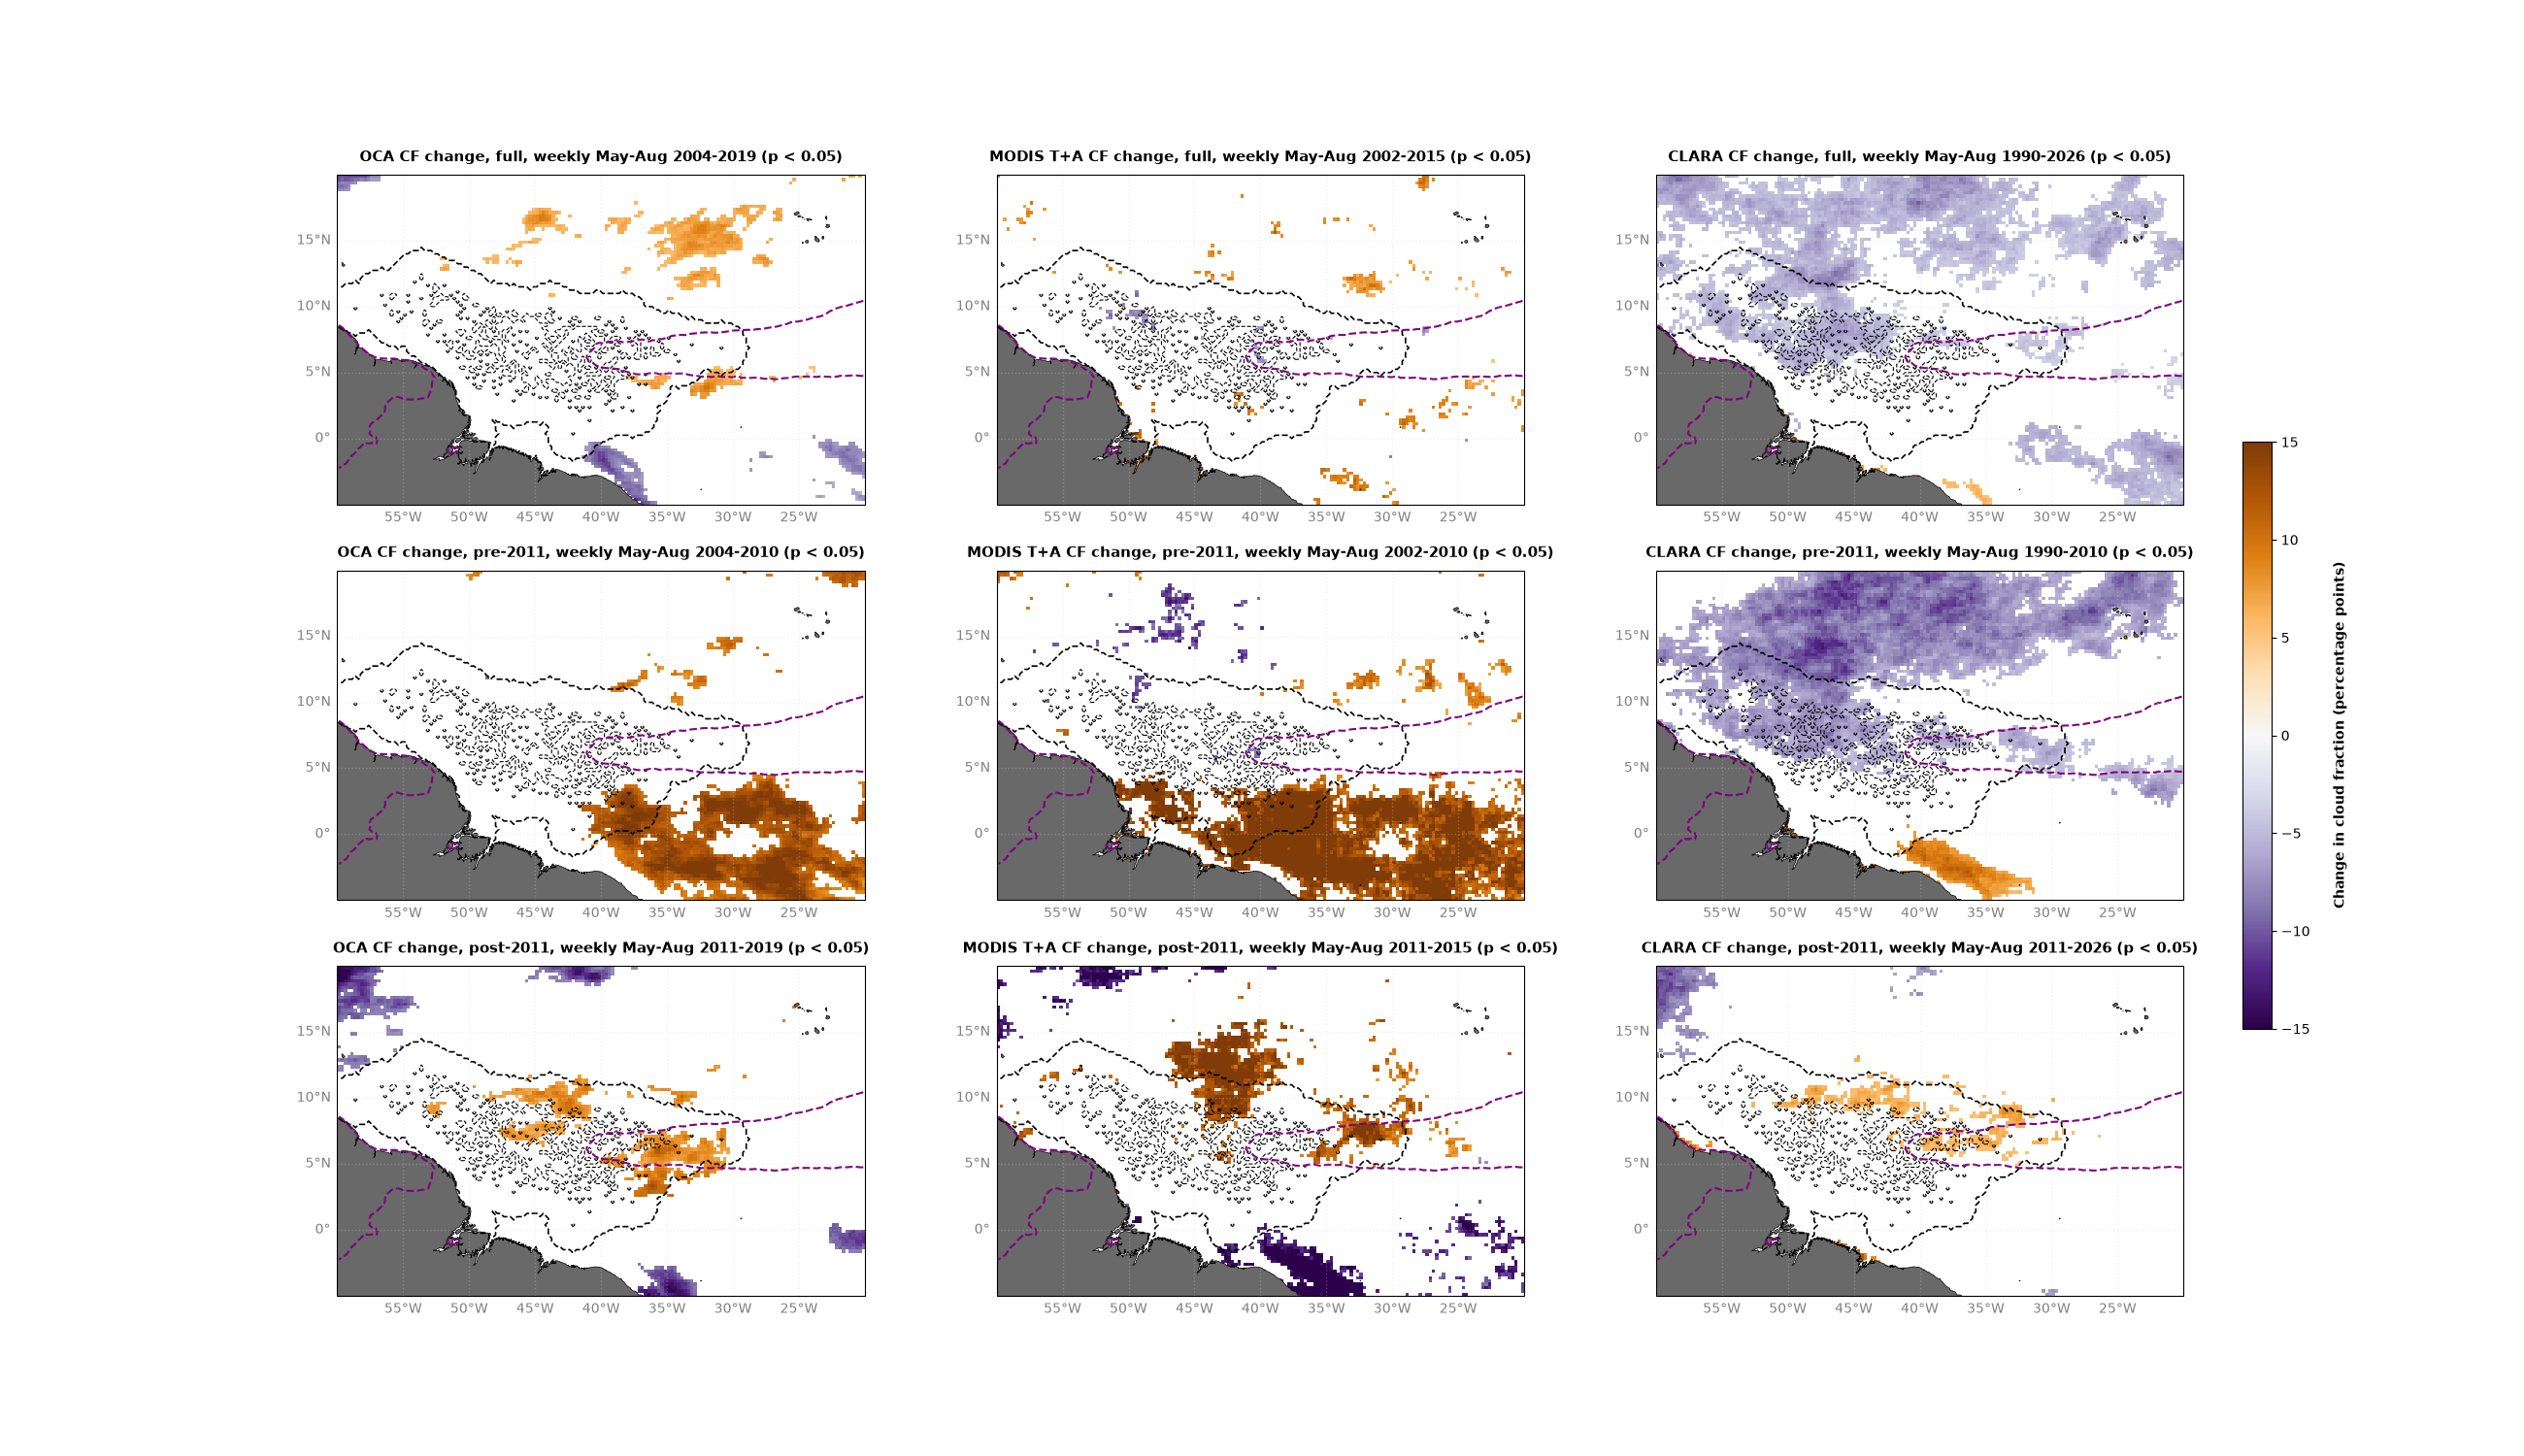

In [13]:
fig, axes = plt.subplots(3, 3, figsize = (26, 15), subplot_kw = dict(projection = pc))

for col, name in enumerate(["OCA", "MODIS T+A", "CLARA"]):
    for row, block in enumerate(["full", "pre-2011", "post-2011"]):
        ax = axes[row, col]
        data, years = pix[(name, block)]
        im = ax.pcolormesh(data.lon, data.lat, data, cmap = 'PuOr_r', transform = pc)
        im.set_clim(-15, 15)
        # Sargassum belt and outer edge of the ring
        ax.contour(belt.lon, belt.lat, belt.astype(float), levels = [0.5], colors = 'black',
                   linestyles = '--', linewidths = 0.8, transform = pc)
        ax.contour(belt.lon, belt.lat, (belt | ring).astype(float), levels = [0.5], colors = 'black',
                   linestyles = '--', linewidths = 1.2, transform = pc)
        ax.contour(olr_mean.lon, olr_mean.lat, olr_mean, levels = [240], colors = 'purple',
                   linestyles = '--', linewidths = 1.5, transform = pc)
        ax.set_extent([-60, -20, -5, 20], crs = pc)
        ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '10m', linewidth = 0.5,
                                                     edgecolor = 'black', facecolor = 'dimgrey'))
        gl = ax.gridlines(crs = pc, draw_labels = True, linewidth = 1, color = 'lightgray', alpha = 0.3, linestyle = ':')
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = {'size': 10, 'color': 'grey'}
        gl.ylabel_style = {'size': 10, 'color': 'grey'}
        ax.set_title(f"{name} CF change, {block}, weekly May-Aug {years} (p < 0.05)", fontsize = 11, weight = 'bold',
                     pad = 10, y = 1.0)

cbar = fig.colorbar(im, ax = axes, orientation = "vertical", fraction = 0.015, pad = 0.03)
cbar.set_label("\nChange in cloud fraction (percentage points)", fontsize = 10, weight = 'bold')
plt.show()

In [14]:
fig.savefig('Sargassum_belt_pixel_trends_OLR.png', dpi = 300)

### Plot ▶▶ weekly belt minus ring, with pre- and post-2011 means

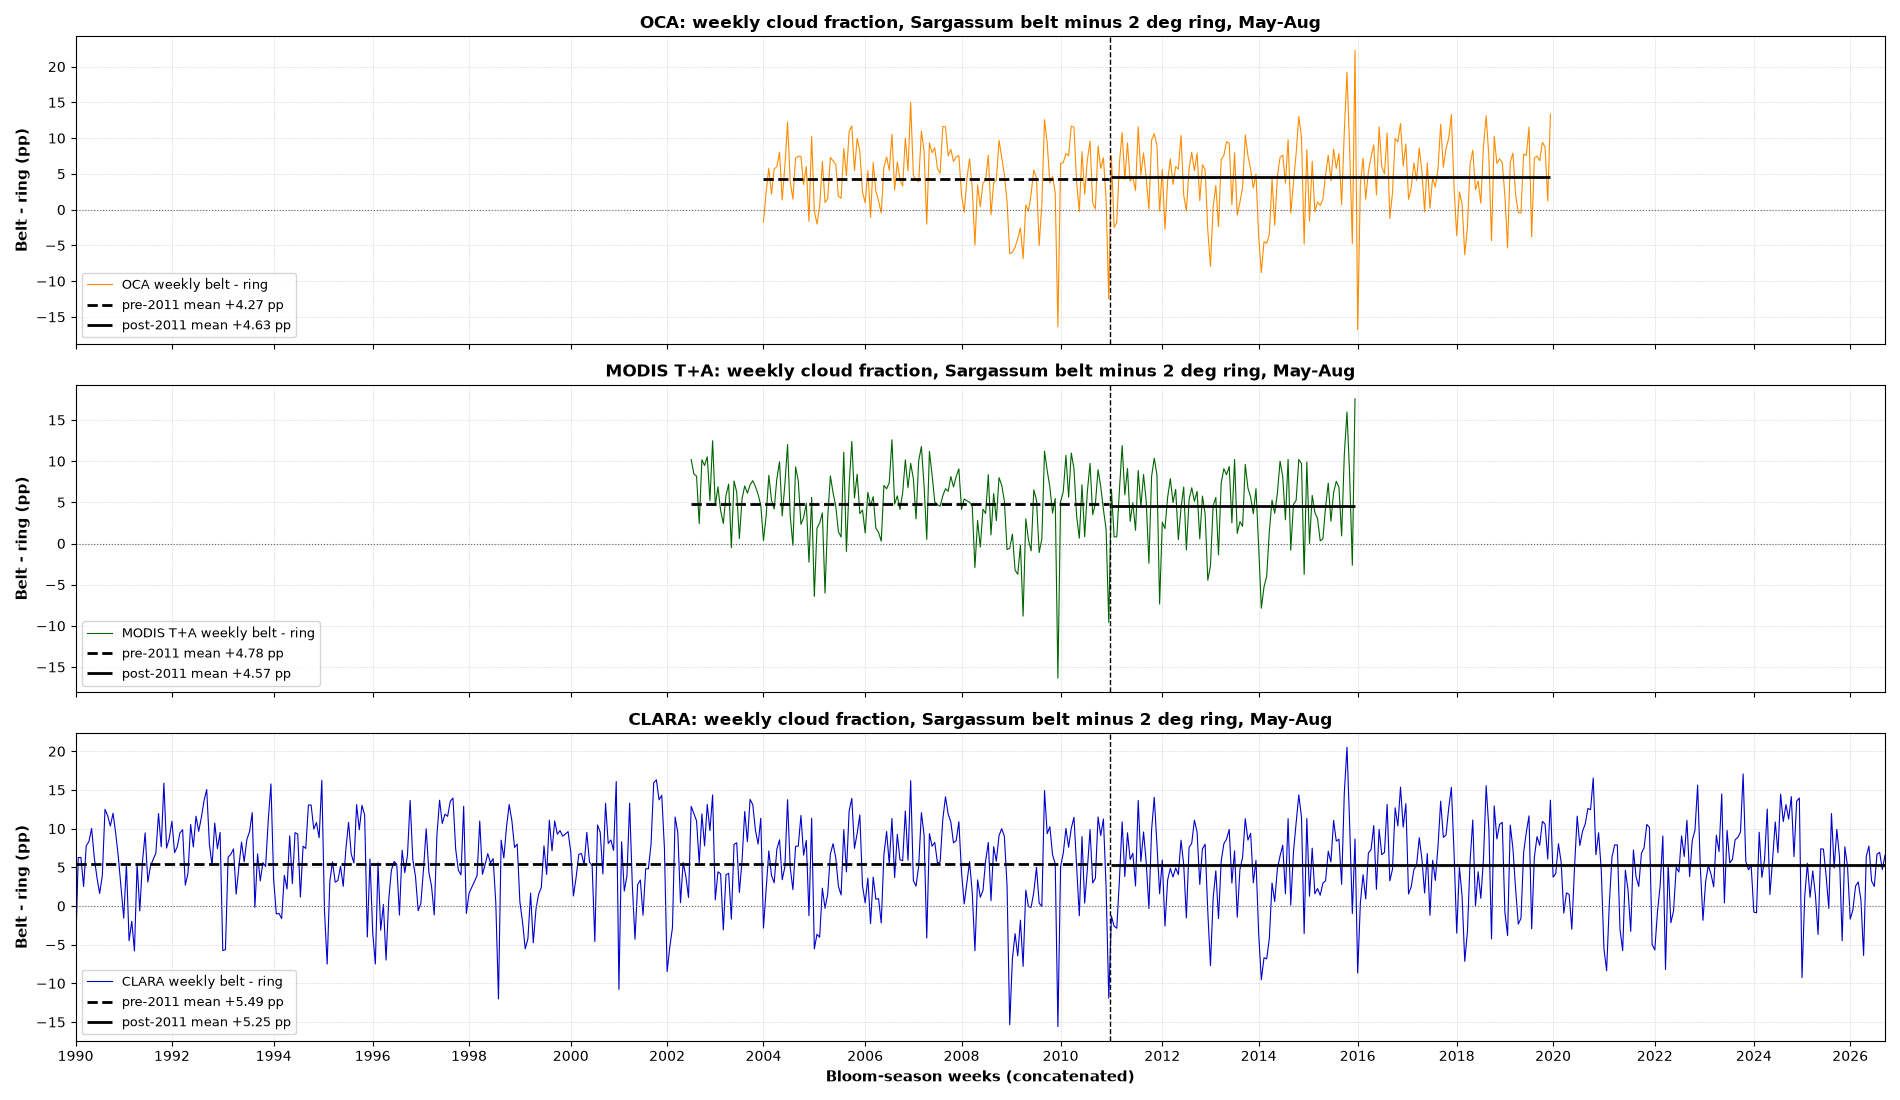

In [15]:
idx = weekly["CLARA"].index.union(weekly["OCA"].index).union(weekly["MODIS T+A"].index)
seq = pd.Series(range(len(idx)), index = idx)
first_weeks = seq.groupby(seq.index.year).min()
colours = {"OCA": 'darkorange', "MODIS T+A": 'darkgreen', "CLARA": 'mediumblue'}

fig, axes = plt.subplots(3, 1, figsize = (19, 11), sharex = True)
for ax, (name, w) in zip(axes, weekly.items()):
    ax.plot(seq[w.index], w["diff"], linewidth = 0.8, color = colours[name], label = f"{name} weekly belt - ring")
    for block, d in [("pre", w[w.index < SPLIT]), ("post", w[w.index >= SPLIT])]:
        ax.hlines(d["diff"].mean(), seq[d.index].min(), seq[d.index].max(), color = 'black',
                  linewidth = 2.0, linestyle = '--' if block == "pre" else '-',
                  label = f"{block}-2011 mean {d['diff'].mean():+.2f} pp")
    ax.axhline(0, color = 'dimgrey', linestyle = ':', linewidth = 0.8)
    ax.axvline(seq[seq.index >= SPLIT].min() - 0.5, color = 'black', linestyle = '--', linewidth = 1.0)
    ax.set_ylabel('Belt - ring (pp)', fontsize = 11, weight = 'bold')
    ax.set_title(f'{name}: weekly cloud fraction, Sargassum belt minus 2 deg ring, May-Aug', fontsize = 12, weight = 'bold')
    ax.grid(True, color = 'silver', linestyle = ':', linewidth = 0.5)
    ax.legend(loc = 'lower left', fontsize = 9)
    ax.margins(x = 0)
axes[-1].set_xticks(first_weeks.values[::2])
axes[-1].set_xticklabels(first_weeks.index[::2])
axes[-1].set_xlabel('Bloom-season weeks (concatenated)', fontsize = 11, weight = 'bold')
plt.tight_layout()
plt.show()

In [16]:
fig.savefig('Sargassum_belt_minus_ring_weekly.png', dpi = 300)